## Análisis de sensibilidad y optimización

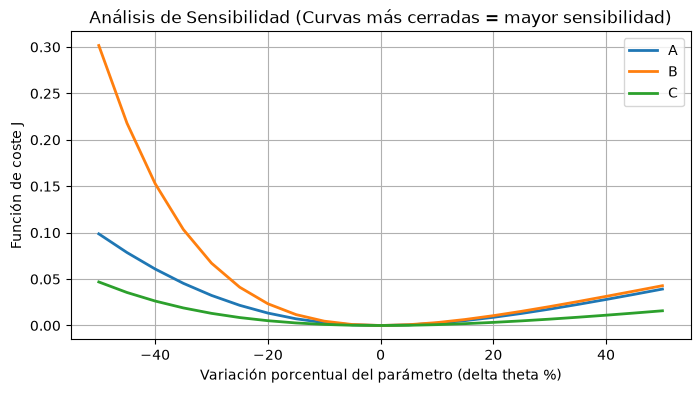

Valores semilla iniciales: [10. 10.]
Parámetros óptimos encontrados [A*B, B*C]: [2.4000023  1.19996778]
Coste mínimo alcanzado J: 7.18643085747917e-11


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import TransferFunction, lsim
from scipy.optimize import minimize

# ---------------------------------------------------------
# 1. DEFINICIÓN DEL MODELO MATEMÁTICO: G(s) = 1 / (AB*s^2 + BC*s + 1)
# ---------------------------------------------------------
def fn_sys(params, t, u):
    A, B, C = params[0], params[1], params[2]
    num = [1]
    den = [A * B, B * C, 1]  # Coeficientes del polinomio denominador[cite: 13]
    system = TransferFunction(num, den)
    # lsim retorna (tiempo, salida, estados); desempaquetamos la salida predicha[cite: 13]
    _, y_pred, _ = lsim(system, U=u, T=t)
    return y_pred

# Datos de ejemplo para ejecutar el script (en tu taller los cargas de 'signals.csv')[cite: 12]
t = np.linspace(0, 10, 500)
u_filt = np.sin(2 * np.pi * 1.5 * t)               # Entrada filtrada[cite: 12, 13]
pararef = np.array([5.0, 0.5, 2.0])                # Valores nominales sujeto 1: A, B, C[cite: 12, 13]
y_s1 = fn_sys(pararef, t, u_filt)                  # Salida referencia sujeto 1[cite: 12, 13]
y_s2 = fn_sys([3.0, 0.8, 1.5], t, u_filt)          # Salida objetivo sujeto 2 (a identificar)[cite: 12]

# ---------------------------------------------------------
# 2. ANÁLISIS DE SENSIBILIDAD (Perturbación -50% a +50%)[cite: 13]
# ---------------------------------------------------------
Np = 3
step = 5
para_change = np.arange(-50, 51, step)             # Variaciones porcentuales[cite: 13]
num_steps = len(para_change)
J_sens = np.zeros((num_steps, Np))

for i in range(Np):                                # Itera sobre cada parámetro (A, B, C)[cite: 13]
    for k in range(num_steps):                     # Itera sobre cada cambio porcentual[cite: 13]
        para = pararef.copy()
        para[i] = pararef[i] * (1 + para_change[k] / 100.0)
        if para_change[k] == 0:
            J_sens[k, i] = 0
        else:
            ypred = fn_sys(para, t, u_filt)
            e = ypred - y_s1
            J_sens[k, i] = np.sum(e ** 2)          # Función de coste cuadrática[cite: 13]

plt.figure(figsize=(8, 4))
labels = ['A', 'B', 'C']
for i in range(Np):
    plt.plot(para_change, J_sens[:, i], label=labels[i], linewidth=2)
plt.title('Análisis de Sensibilidad (Curvas más cerradas = mayor sensibilidad)')
plt.xlabel('Variación porcentual del parámetro (delta theta %)')
plt.ylabel('Función de coste J')
plt.legend()
plt.grid(True)
plt.show()

# ---------------------------------------------------------
# 3. FUNCIÓN DE COSTE Y OPTIMIZACIÓN CON VALORES SEMILLA[cite: 14]
# ---------------------------------------------------------
def fn_coste(theta):
    # theta[0] representa (A*B) y theta[1] representa (B*C)[cite: 11, 14]
    num = [1]
    den = [theta[0], theta[1], 1]
    system = TransferFunction(num, den)
    _, ypred, _ = lsim(system, U=u_filt, T=t)
    e = y_s2 - ypred
    J = np.sum(e ** 2)                             # Error cuadrático a minimizar[cite: 14]
    return J

# Valores semilla (punto de arranque del optimizador)[cite: 14]
theta_init = np.array([10.0, 10.0])

# Minimización usando el algoritmo Nelder-Mead[cite: 14]
res = minimize(fn_coste, theta_init, method='Nelder-Mead')

print("Valores semilla iniciales:", theta_init)
print("Parámetros óptimos encontrados [A*B, B*C]:", res.x)
print("Coste mínimo alcanzado J:", res.fun)

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq
from scipy.signal import butter, filtfilt
import numpy as np
from scipy.signal import TransferFunction, lsim
from scipy.optimize import minimize

In [18]:
#Cargar datos
df = pd.read_csv('signals.csv')
df.head()

,u,u_r,y_s1,y_s2,t
0,1.000000,1.000000,0.000000e+00,0.000000e+00,0.00
1,1.139468,1.727253,8.076038e-09,6.730189e-09,0.01
2,1.185334,0.234277,2.906984e-07,2.422827e-07,0.02
3,1.150999,2.102055,7.754828e-06,6.467055e-06,0.03
4,1.057618,0.469833,1.997329e-05,1.666384e-05,0.04


In [19]:
#Reescribir las variables

t = df.t
u = df.u
u_r = df.u_r
y_s1 = df.y_s1
y_s2 = df.y_s2

Text(0.5, 0, 'Tiempo (s)')

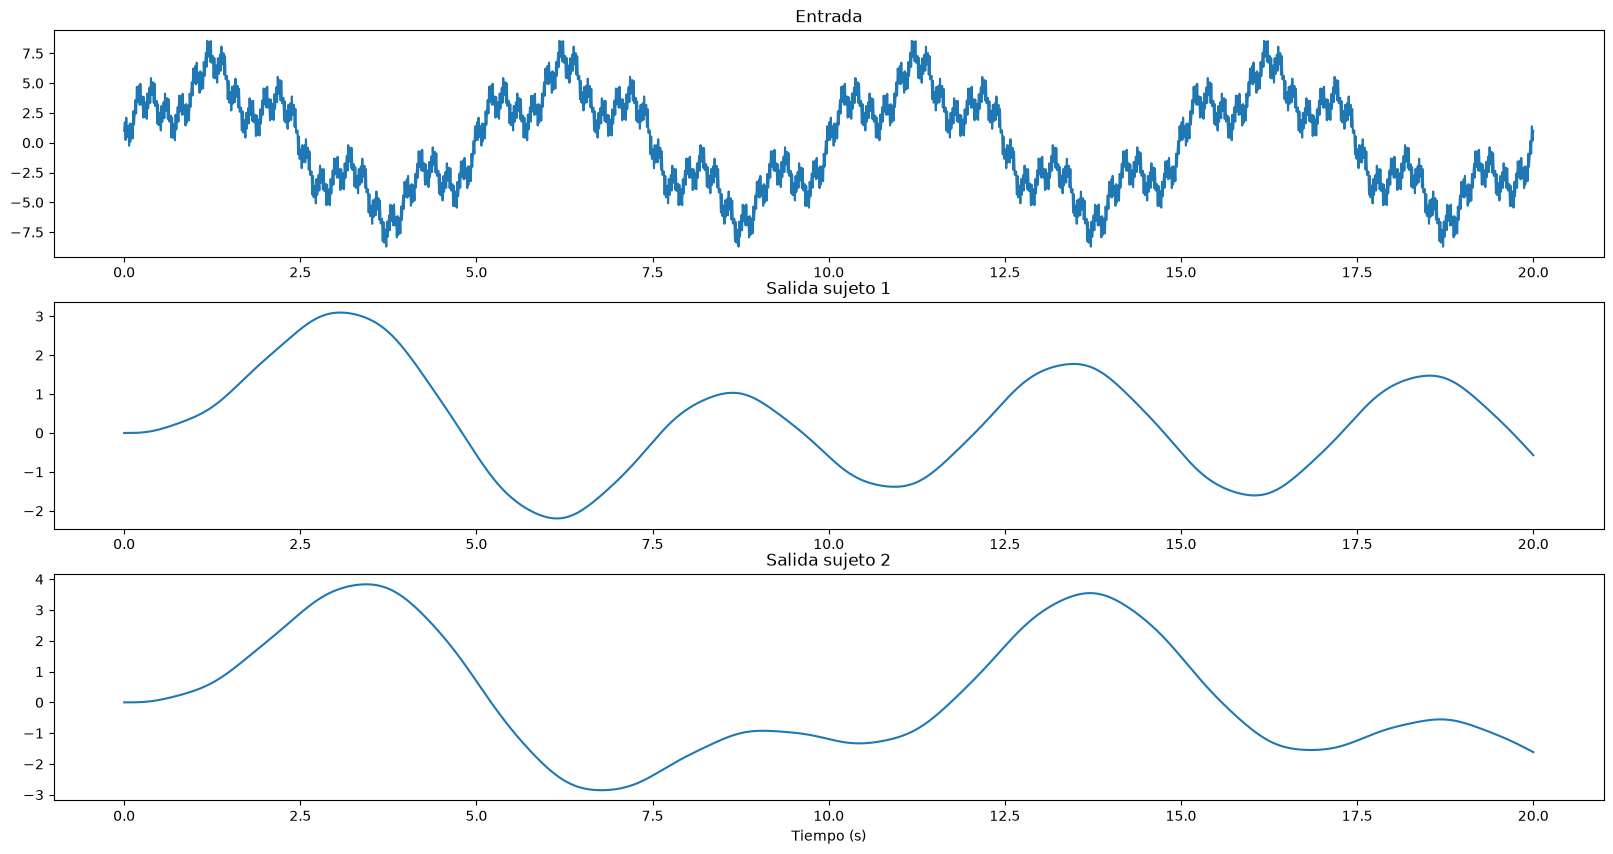

In [20]:
#Graficar para inspeccionar los datos
# Inspección de datos

plt.figure(figsize=(20, 10))
plt.subplot(3, 1, 1)
plt.plot(t, u_r)
plt.title('Entrada')

plt.subplot(3, 1, 2)
plt.plot(t, y_s1)
plt.title('Salida sujeto 1')

plt.subplot(3, 1, 3)
plt.plot(t, y_s2)
plt.title('Salida sujeto 2')
plt.xlabel('Tiempo (s)')


#En la identificación paramétrica el rudio estaba afectando a la señal de salida, entonces se agregaba para poder identificar el sistema.
#En los ejercicios de sensibilidad y optimización el ruido afecta la señal de entrada, y eso afecta la sensibilidad de los parámetros

Text(0.5, 0, 'Frecuencia (Hz)')

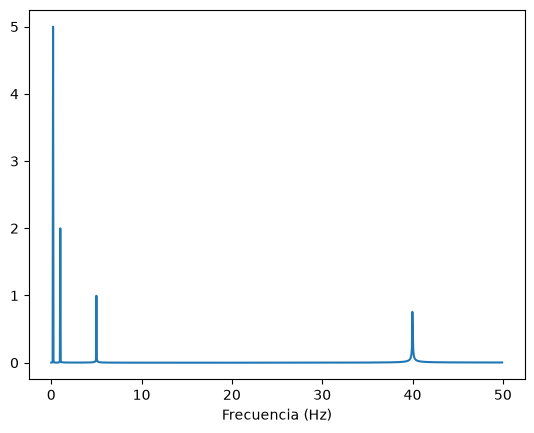

In [21]:
# Revisión de frecuencias que componen la señal
N = len(u_r)
Ts = np.mean(np.diff(t))

yf = fft(u_r)
xf = fftfreq(N, Ts)[:N//2]

plt.plot(xf, 2.0/N * np.abs(yf[0:N//2]))
plt.xlabel("Frecuencia (Hz)")

In [22]:
#Rechazabanda con frecuncia de corte entre 35 y 45 Hz
# Según las frecuencias que tiene la señal se encuentra que es necesario realizar un filtrado a una

# Diseño del filtro
fs = 1/Ts
b, a = butter(3, [35, 45] , btype='stop', fs=fs) #TAREA : HACERLO CON PASA BAJAS
#Frecuencias de corte 35,45
# Aplicación del filtro
u_filt = filtfilt(b, a, u_r)

# Revisión éxito de filtrado

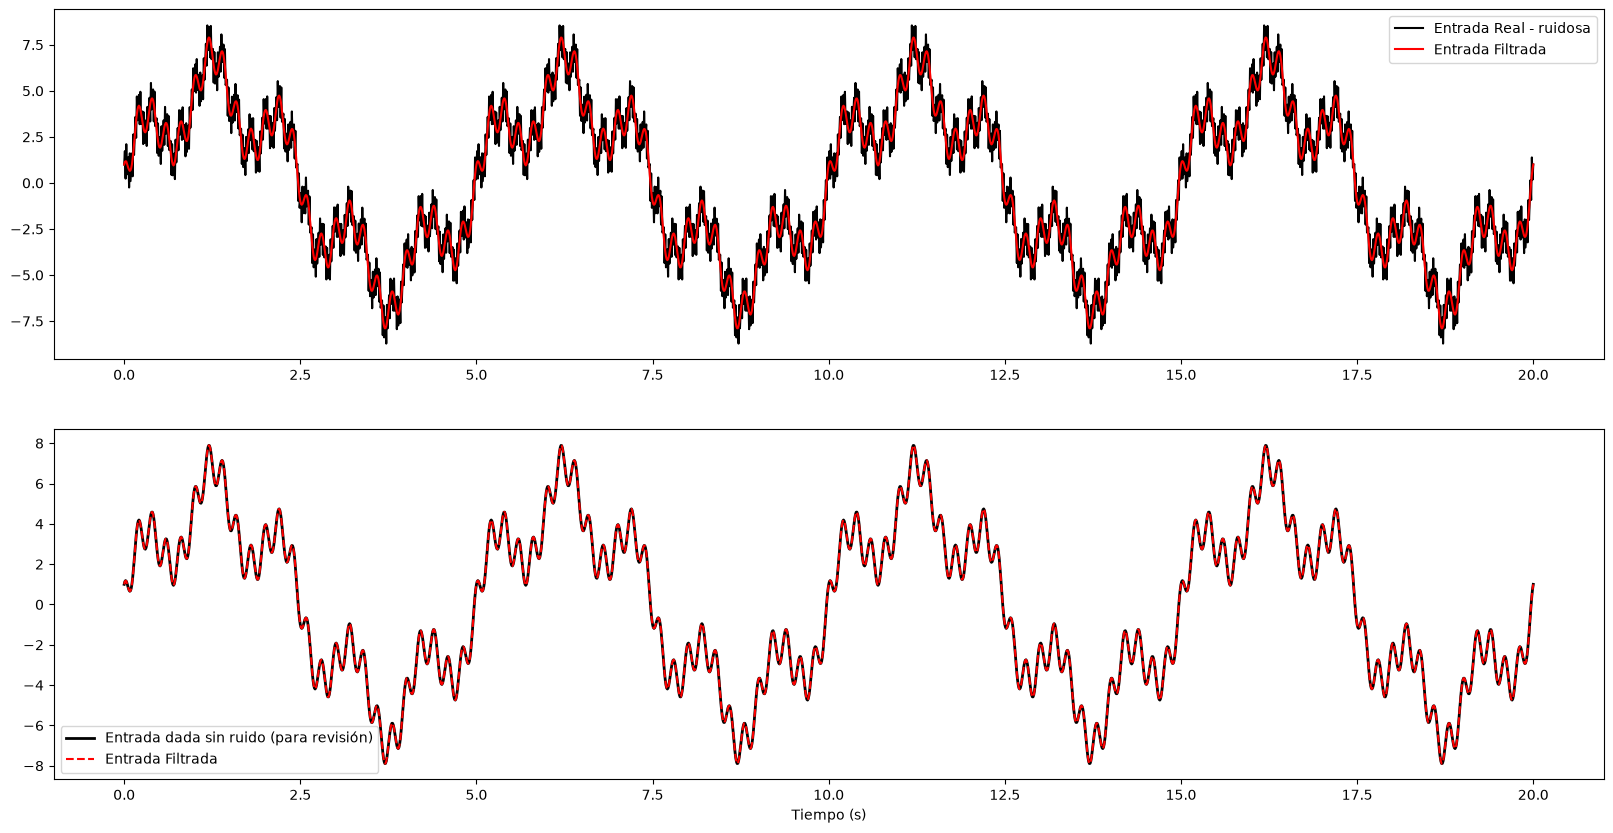

In [23]:
#Tarea con filtro pasa-bajas
# Según las frecuencias que tiene la señal se encuentra que es necesario realizar un filtrado a una

# Diseño del filtro
fs = 1/Ts
b, a = butter(3, [35, 45] , btype='stop', fs=fs) #TAREA : HACERLO CON PASA BAJAS

# Aplicación del filtro
u_filt = filtfilt(b, a, u_r)

# Revisión éxito de filtrado
plt.figure(figsize=(20, 10))
plt.subplot(2, 1, 1)
plt.plot(t, u_r, 'k',label='Entrada Real - ruidosa')
plt.plot(t, u_filt, 'r', label='Entrada Filtrada')
plt.legend()


plt.subplot(2, 1, 2)
plt.plot(t, u, 'k', label='Entrada dada sin ruido (para revisión)', linewidth=2)
plt.plot(t, u_filt, 'r', label='Entrada Filtrada', linestyle='--')
plt.xlabel('Tiempo (s)')
plt.legend()

In [24]:
# Define la función del sistema recibiendo el vector de parámetros (params), el vector de tiempo (t) y la señal de entrada (u)
def fn_sys(params, t, u):

    # Extrae el primer elemento del arreglo como el parámetro A
    A = params[0]
    # Extrae el segundo elemento del arreglo como el parámetro B
    B = params[1]
    # Extrae el tercer elemento del arreglo como el parámetro C
    C = params[2]

    # Define los coeficientes del polinomio del denominador: (A*B)s^2 + (B*C)s + 1
    den = [A*B, B*C, 1]
    # Define el numerador constante de la función de transferencia igual a 1
    num = 1
    # Construye el modelo continuo del sistema LTI (función de transferencia) mediante SciPy
    system = TransferFunction(num, den)

    # Simula la respuesta del sistema ante la entrada U=u en el vector de tiempo T=t, guardando únicamente la salida predicha (y_pred)
    _, y_pred, _ = lsim(system, U=u, T=t)

    # Retorna el arreglo con la señal de salida simulada del modelo
    return y_pred

In [25]:
# Define el número total de parámetros del modelo a evaluar (A, B y C)
Np = 3

# Crea un arreglo con los valores nominales de referencia del sujeto 1: A=5, B=0.5 y C=2
pararef = np.array([5, 0.5, 2])

# Inicializa un vector columna de ceros con la misma longitud que pararef
para = np.zeros((len(pararef), 1))

# Establece el incremento porcentual (5%) entre cada prueba de perturbación
step = 5

# Genera el arreglo de variaciones porcentuales desde -50% hasta +50% de 5 en 5
para_change = np.arange(-50, 51, step)

# Calcula la cantidad total de evaluaciones por parámetro (21 pasos en total)
num_steps = int(2*(50/step) + 1)

# Inicializa la matriz J (21 filas x 3 columnas) donde se guardará el coste de cada prueba
J = np.zeros((num_steps, Np))

# Bucle externo: itera sobre cada parámetro del sistema (i=0 para A, i=1 para B, i=2 para C)
for i in range(Np):
    # Bucle interno: itera sobre cada porcentaje de variación k dentro de los 21 pasos
    for k in range(num_steps):
        # Crea una copia limpia de los valores nominales para aislar el cambio en un solo parámetro
        para = pararef.copy()
        # Aplica la variación porcentual k únicamente al parámetro i actual
        para[i] = pararef[i] * (1 + para_change[k] / 100)
        # Comprueba si la perturbación es del 0% (parámetros iguales a los de referencia)
        if para_change[k] == 0:
            # Asigna un coste de 0 sin simular, ya que no hay diferencia con la salida nominal
            J[k, i] = 0
        # Si la perturbación es distinta de 0%, ejecuta la simulación y calcula el error
        else:
            # Simula la respuesta del sistema con el parámetro perturbado y la entrada filtrada
            ypred = fn_sys(para, t, u_filt)
            # Calcula la diferencia (error residual) entre la salida simulada y la real del sujeto 1
            e = ypred - y_s1
            # Calcula la suma de errores al cuadrado (función de coste J) y la guarda en la matriz
            J[k, i] = np.sum(e ** 2)

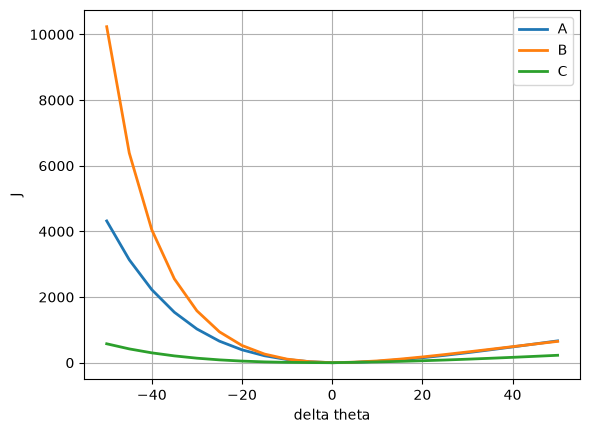

In [26]:

# Plotting
plt.figure()
labels = ['A', 'B', 'C']   # According to class example
for i in range(Np):
    plt.plot(para_change, J[:, i], label=labels[i], linewidth=2)
plt.legend()
plt.xlabel('delta theta')
plt.ylabel('J')
plt.grid(True)
plt.show()

#C es el parametro menos sensible y C es el parametro más sensible.
#B es mucho más sensible a cambios negativos que a cambios positivos.

## Optimización

Se escoje para ajustar y optimizar el parámetro más sensible, porque pequeños cambios en ese parámetro modifican la sálida

In [29]:
# Define la función objetivo que recibe el arreglo de parámetros candidatos theta = [theta[0], theta[1]]
def fn_coste(theta):
    # Permite acceder dentro de la función a las variables externas de tiempo (t), entrada (u) y salida real del sujeto 2 (y_s2)
    global t, u, y_s2

    # Define los coeficientes del polinomio del denominador: theta[0]*s^2 + theta[1]*s + 1
    den = [theta[0], theta[1], 1]
    # Define el numerador constante de la función de transferencia igual a 1
    num = [1]

    # Construye el modelo continuo del sistema LTI (función de transferencia) mediante SciPy
    system = TransferFunction(num, den)

    # Simula la respuesta temporal del sistema ante la entrada U=u en el vector de tiempo T=t, extrayendo la salida predicha (ypred)
    _, ypred, _ = lsim(system, U=u, T=t)

    # Calcula el error residual punto a punto entre la salida medida del sujeto 2 y la salida simulada
    e = y_s2 - ypred
    # Calcula la suma de los errores al cuadrado para obtener el valor escalar de la función de coste J
    J = np.sum(e**2)

    # Retorna el valor de coste J que el algoritmo de optimización buscará minimizar
    return J

In [27]:
# Define el valor nominal del parámetro A igual a 5
A = 5
# Define el valor nominal del parámetro B igual a 0.5
B = 0.5
# Define el valor nominal del parámetro C igual a 2
C = 2

# Define el arreglo con los valores semilla (estimación inicial) para los dos parámetros a optimizar
theta_init = np.array([20, 20])

# Ejecuta la minimización de la función de coste (fn_coste) partiendo de theta_init usando el método Nelder-Mead
res = minimize(fn_coste, theta_init, method='Nelder-Mead')

# Imprime un salto de línea y un encabezado en la consola para presentar los resultados
print('\nValores de theta obtenidos:')
# Imprime únicamente el arreglo con los valores óptimos encontrados para los parámetros
print(res.x)
# Imprime el resumen completo del proceso de optimización (estado de convergencia, número de iteraciones, valor mínimo del coste, etc.)
print(res)


Valores de theta obtenidos:
[3.01556247 0.14626221]
       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 4.0960579077579276
             x: [ 3.016e+00  1.463e-01]
           nit: 54
          nfev: 103
 final_simplex: (array([[ 3.016e+00,  1.463e-01],
                       [ 3.016e+00,  1.462e-01],
                       [ 3.016e+00,  1.463e-01]]), array([ 4.096e+00,  4.096e+00,  4.096e+00]))


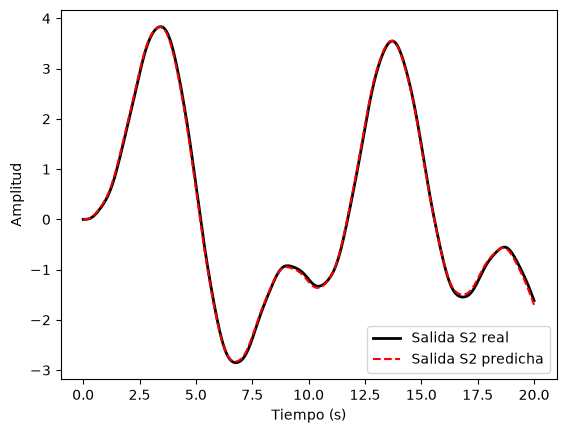

In [30]:
# Creación de la salida con los parámetros obtenidos tras optimización
den = [res.x[0], res.x[1], 1]
num = [1]
system = TransferFunction(num, den)
_, ypred_s2, _ = lsim(system, U=u_filt, T=t)

plt.plot(t, y_s2, 'k', label='Salida S2 real', linewidth=2)
plt.plot(t, ypred_s2, 'r', label='Salida S2 predicha', linestyle='--')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.legend()